# Simulations with SpynDynamica

The numeric engine of SpynDynamica, the Python port in progress of
[SpinDynamica](https://www.spindynamica.soton.ac.uk): sequences of pulses and delays with strong coupling and
relaxation, signals with their Fourier transform, the isotope table, time-dependent and periodic Hamiltonians,
ensemble and powder averages, density operators, and chemical exchange. Two examples run in the browser
playground with nothing installed: a [strongly coupled pair](https://ajerschow.github.io/spynach/try.html#ex-sd-ab) and
[two-site exchange](https://ajerschow.github.io/spynach/try.html#ex-sd-exchange). The operators, bases and superoperators it works with are
described in [Symbolic spin operators with SpynDynamica](spyndynamica.ipynb);
the [table of SpinDynamica names](coming-from-spindynamica.ipynb#Names) and the list of differences are in
[Coming from SpinDynamica](coming-from-spindynamica.ipynb).

SpinDynamica is the work of Malcolm H. Levitt and co-authors. Work that uses SpynDynamica should cite
C. Bengs, M. H. Levitt, *SpinDynamica: Symbolic and numerical magnetic resonance in a Mathematica environment*, Magn. Reson. Chem. (2017), doi:10.1002/mrc.4642.

*Generated from [`docs/spyndynamica-simulations.md`](../spyndynamica-simulations.md) by `docs/build_notebooks.py`; edit the Markdown guide, not this notebook.*

Run the cells in order: later cells use names defined by earlier ones. The saved outputs come from running the notebook top to bottom; plotting cells need Plotly (`pip install -e ".[docs]"`).

## Contents

1. [Setup](#Setup)
2. [Pulse sequences, strong coupling and relaxation](#Pulse-sequences,-strong-coupling-and-relaxation)
3. [Signals and spectra](#Signals-and-spectra)
4. [Two-dimensional spectra](#Two-dimensional-spectra)
5. [Isotopes and interactions](#Isotopes-and-interactions)
6. [Time-dependent Hamiltonians](#Time-dependent-Hamiltonians)
7. [Ensemble and powder averages, tensors](#Ensemble-and-powder-averages,-tensors)
8. [Density operators, secular parts and optimisation](#Density-operators,-secular-parts-and-optimisation)
9. [Chemical exchange](#Chemical-exchange)

## Setup

The examples use two spins-1/2 and a relaxation superoperator with symbolic time constants.

In [1]:
import sympy as sp

from spyndynamica import SpinSystem, phenomenological_relaxation

s = SpinSystem(2)
I = s.I
T1, T2 = sp.symbols("T1 T2", positive=True)
relaxation = phenomenological_relaxation(s, T1, T2)

## Pulse sequences, strong coupling and relaxation

The numeric engine takes a list of events. `(H, t)` is evolution under a Hamiltonian for a time,
`Pulse(flip, phase)` an ideal pulse, `Delay(t)` an interval under the background, `Repeat(events, n)` a loop,
and a superoperator acts instantaneously. `background` acts during every event with a duration. Strong coupling
needs no special handling here.

In [2]:
import numpy as np

from spyndynamica import Delay, Pulse, amplitudes, propagate, trajectory

strong = 2 * sp.pi * 100 * I(1, "z") - 2 * sp.pi * 40 * I(2, "z") + 2 * sp.pi * 7 * s.dot(1, 2)
echo = [Pulse(sp.pi / 2, "x"), Delay(0.004), Pulse(sp.pi, "y"), Delay(0.004)]

print(amplitudes(I(1, "z"), [I(1, "y"), 2 * I(1, "x") @ I(2, "z")], echo, background=strong).round(4))
print(propagate(I(1, "z"), echo, background=strong).round(3)[0])

[-0.9798-0.j  0.1742-0.j]
[0.   +0.j    0.087+0.49j  0.001-0.049j 0.   +0.j   ]


`amplitudes` is SpinDynamica's `TransformationAmplitude`, `propagate` its `NPropagate` (the result is the
density matrix as a NumPy array), and `propagator` gives the unitary. Symbols in the events get numbers
through `values`, and a relaxation superoperator in the background switches the engine to Liouville space:

In [3]:
values = {T1: 2.0, T2: 0.2}
times, decay = trajectory(I(1, "x"), I(1, "x"), [Delay(0.3)], points=3, background=[strong, relaxation], values=values)
print(times.round(2), np.abs(decay).round(4))

[0.  0.1 0.2 0.3] [1.     0.3417 0.1113 0.1949]


For larger spin systems the engine keeps the Hamiltonians sparse and diagonalises them block by block: a
Hamiltonian that conserves a quantity such as the total `Iz` falls into independent blocks, which are found
automatically. `method="auto"` (the default) does this from a Hilbert-space dimension of 128 on; `"dense"` and
`"sparse"` force one or the other.

In [4]:
ten = SpinSystem(10)
chain = sum((2 * sp.pi * 100 * j * ten.I(j, "z") for j in range(1, 11)), ten.zero())
chain = chain + sum((2 * sp.pi * 7 * ten.dot(j, j + 1) for j in range(1, 10)), ten.zero())

signal = amplitudes(ten.I(None, "z"), [ten.I(1, "x"), ten.I(1, "y")], [Pulse(sp.pi / 2, "x"), (chain, 0.01)])
print(ten.dimension, signal.real.round(4))

1024 [-0.0073 -0.976 ]


A `PulseSequence` groups events. It gives its pulses default spins and a common phase shift, and with a total
`duration` it stretches `Delay("auto")` to fit; several `Delay(("auto", weight))` share the remaining time.
`ShapedPulse` takes the amplitude, phase and frequency offset as expressions of a local time, and
`precalculate` stores the propagator of a block for reuse, as a `Precalculated` event.

In [5]:
from spyndynamica import PulseSequence, ShapedPulse, precalculate

local = sp.Symbol("tau", real=True)
block = PulseSequence([Pulse(sp.pi / 2, "x"), Delay("auto"), Pulse(sp.pi, "y"), Delay("auto")], duration=0.008)
print(round(amplitudes(I(1, "z"), I(1, "y"), [block], background=strong).real, 4))

gaussian = ShapedPulse(0.01, 2 * sp.pi * 80 * sp.exp(-((local / 0.002) ** 2)), tau=local, spins=[1])
print(amplitudes(I(1, "z"), [I(1, "y"), I(1, "z")], [gaussian]).real.round(4))

stored = precalculate([block], background=strong)
print(round(amplitudes(I(1, "z"), I(1, "y"), [stored, stored], background=strong).real, 4))

-0.9798
[-0.978  -0.2088]
0.0003


A coherence-order filter is an event like any other superoperator: `coherence_filter(s, [-2, 2])` in the
list. `Pulse` also takes `phase_shift` and `amplitude_factor`, and `amplitudes` takes `start_time` (the time
at which the sequence starts) and `normalization`.

`trajectory` samples the amplitudes during the sequence, and `superpropagator` is the propagator of the events
in Liouville space, the counterpart of `propagator` when relaxation is present. A pulse with `nutation_frequency` or `duration` has a
finite length, and the background acts during it. Events run from left to right; `order="right_to_left"`
reverses them for one call.

## Signals and spectra

`signal_1d` is SpinDynamica's `Signal1D`: the free-induction decay of a spin system under a Hamiltonian. By
default the system starts from `Iz` of all spins, a 90° pulse about x prepares it, and the observable is
`−(i/2) I−` of all spins. The signal is the amplitude `(Q|ρ(t))/(Q|Q)` of the observable `Q`, so it starts at 1
and a Hamiltonian `ω Iz` gives `exp(+iωt)`.

In [6]:
from spyndynamica import ft, signal_1d

ab = 2 * sp.pi * 30 * I(1, "z") - 2 * sp.pi * 10 * I(2, "z") + 2 * sp.pi * 12 * s.dot(1, 2)
fid = signal_1d(ab, points=256, bandwidth=2 * sp.pi * 200, line_broadening=2 * np.pi * 1)

for amplitude, omega, decay in fid.peaks:
    print(f"{omega.real / (2 * np.pi):8.3f} Hz   amplitude {amplitude.real:.4f}   decay rate {decay.real:.3f} /s")
print(fid.values[:3].round(4))

  36.881 Hz   amplitude 0.1782   decay rate 3.142 /s
  24.881 Hz   amplitude 0.3218   decay rate 3.142 /s
  -4.881 Hz   amplitude 0.3218   decay rate 3.142 /s
 -16.881 Hz   amplitude 0.1782   decay rate 3.142 /s
[1.    +0.j     0.7595+0.2468j 0.2667+0.1938j]


Frequencies and line widths are in rad/s. `bandwidth` sets the dwell time `2π / bandwidth`; `dwell` gives it
directly. For a time-independent Hamiltonian the signal is a list of peaks, one per transition, from which
`values` are the samples; `method="direct"` propagates step by step instead. `line_broadening` is a full width
at half height, `"auto"` (the default, 1% of the envelope at the last sample) or `None`. With a relaxation
superoperator in `background` the Liouvillian is diagonalised and every peak has its own decay rate.

`ft` returns the frequency axis in Hz and the spectrum:

In [7]:
frequencies, spectrum = ft(fid)
print(len(frequencies), frequencies[[0, -1]].round(2))
print("tallest line at", frequencies[np.argmax(spectrum.real)].round(2), "Hz")

512 [-99.61 100.  ]
tallest line at 25.0 Hz


The transform is `S(f) = (1/N) Σ s(t_n) exp(−2πi f t_n)`, with the first sample halved and the signal zero
filled to twice its length (`first_point`, `zero_fill`). `lorentzian`, `absorption`, `dispersion` and
`gaussian` are the lineshape functions. A signal is a `Signal` object, sampled data or a list of peaks;
`signal.broadened(width)`, or `apply_line_broadening(signal, width)`, applies line broadening afterwards.
`frequency_axis(points, dwell, zero_fill)` is the frequency axis alone, and `combine_data(datasets, weights)`
adds up arrays or signals with weights (their mean without weights); signals that hold peaks give a signal
with all the weighted peaks.

## Two-dimensional spectra

SpinDynamica has no routine for a two-dimensional signal, and neither has the port: the signal is a matrix
that a loop over the evolution time fills, one free-induction decay per row. `ft2` transforms it along both
dimensions with the conventions of `ft`. The rows belong to the indirect dimension `t1` and the columns to
the direct one `t2`; `zero_fill` and `first_point` take one value or a pair `(direct, indirect)`.

The example is the strongly coupled pair of the last section. Its magnetisation precesses for `t1`, and what
is left along x, or along y, is detected. The two data sets are modulated in `t1` by a cosine and by a sine;
their combinations `cosine ± i sine` are the antiecho and the echo signal, with opposite frequencies in `t1`.

In [8]:
from spyndynamica import combine_complementary_spectra, frequency_axis, ft2, reflect_spectrum

points, dwell, width = 64, 0.005, 2 * np.pi * 2
x_total, y_total = I(None, "x"), I(None, "y")
detected = signal_1d(ab, points=points, dwell=dwell, line_broadening=width).values
t1 = dwell * np.arange(points)
left = np.array([amplitudes(x_total, [x_total, y_total], [(ab, t)]).real for t in t1])
left = left * np.exp(-width / 2 * t1)[:, None]
cosine, sine = left[:, 0, None] * detected, left[:, 1, None] * detected

antiecho, echo = ft2(cosine + 1j * sine), ft2(cosine - 1j * sine)
absorption = combine_complementary_spectra(antiecho, echo)
print(absorption.shape, np.allclose(absorption, (antiecho + reflect_spectrum(echo)) / 2))

(128, 128) True


Each of the two spectra alone has peaks with a phase twist, absorption mixed with dispersion.
`reflect_spectrum` reflects a spectrum about zero frequency, a two-dimensional one about `ω1 = 0`, and
`combine_complementary_spectra(first, second)` is half the sum of the first spectrum and the reflected
second one: the twist cancels and the real part is in pure absorption.

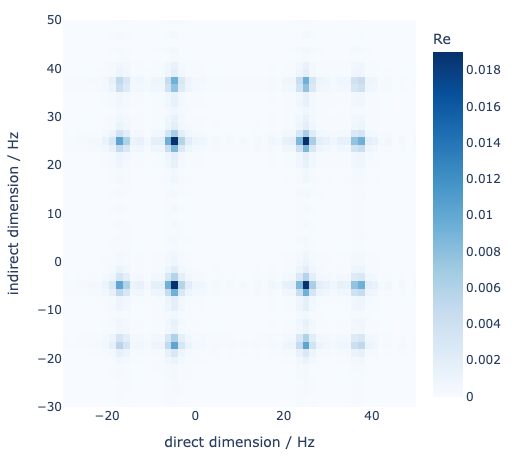

In [9]:
import plotly.graph_objects as go

# a plotly map of the real part, with the frequency axes of the two dimensions
axis = frequency_axis(points, dwell)
figure = go.Figure(go.Heatmap(x=axis, y=axis, z=absorption.real, colorscale="Blues", zmin=0, colorbar=dict(title="Re")))
figure.update_xaxes(title="direct dimension / Hz", range=[-30, 50])
figure.update_yaxes(title="indirect dimension / Hz", range=[-30, 50])
figure.update_layout(width=520, height=460, margin=dict(l=60, r=20, t=20, b=50), template="plotly_white")
figure

Every transition of the pair appears at its own frequency in both dimensions. The detected signal is the same
for every row here, so there are no cross peaks with a sign pattern; a sequence with a mixing pulse fills the
matrix row by row with `signal_1d(..., initial=state)` in the same way.

## Isotopes and interactions

The isotope table and the constants are SpinDynamica's.

In [10]:
from spyndynamica import dipolar_coupling, larmor_frequency, magnetogyric_ratio, spin_quantum_number

print(spin_quantum_number("2H"), magnetogyric_ratio("13C"))
print(larmor_frequency("1H", 9.4) / (2 * np.pi * 1e6), "MHz")
print(dipolar_coupling("1H", "13C", 1.1e-10) / (2 * np.pi), "Hz")

hd = SpinSystem({"H": spin_quantum_number("1H"), "D": spin_quantum_number("2H")})
print(hd)

1 67282840.0
-400.2282091420298 MHz
-22697.719493885113 Hz
SpinSystem([('H', 1/2), ('D', 1)])


The Larmor frequency is `−γ B0` and the dipolar coupling `−(μ0/4π) γ1 γ2 ħ / r³`, both in rad/s.

## Time-dependent Hamiltonians

A Hamiltonian whose coefficients contain a time symbol is wrapped in `TimeDependent(H, t)` and used as the
generator of an event. `t` is the time since the start of the sequence, and the equation of motion is
integrated numerically (in Liouville space when relaxation is present).

In [11]:
from spyndynamica import TimeDependent

one = SpinSystem(1)
x, y, z = one.I(1)
time = sp.Symbol("t", real=True)
sweep = 2 * sp.pi * 40 * x + 2 * sp.pi * (-200 + 2000 * time) * z

print(amplitudes(z, [x, y, z], [(TimeDependent(sweep, time), 0.2)]).real.round(3))
times, track = trajectory(z, z, [(TimeDependent(sweep, time), 0.2)], points=5)
print(track.real.round(3))

[-0.196 -0.225 -0.955]
[ 1.     0.881  0.731 -0.544 -0.969 -0.955]


The example is a slow frequency sweep through resonance, which inverts the magnetisation.

`signal_1d` takes a `TimeDependent` generator and steps through it. For a `Periodic(H, t, period)` generator
whose period is a whole number of dwell times it uses the COMPUTE method: the propagators of one period give
the whole signal as a list of peaks, the differences of the Floquet frequencies plus multiples of the
rotation frequency.

In [12]:
from spyndynamica import Periodic

rotation = 2 * sp.pi * 1000
modulated = 2 * sp.pi * (300 + 400 * sp.cos(rotation * time)) * z
spinning = Periodic(modulated, time, sp.Rational(1, 1000))
sidebands = signal_1d(spinning, points=64, bandwidth=2 * sp.pi * 8000, line_broadening=2 * np.pi * 5)

for amplitude, omega, _ in sidebands.peaks:
    print(f"{omega.real / (2 * np.pi):7.0f} Hz   {amplitude.real:7.4f}")

   3300 Hz    0.0013
   2300 Hz    0.0197
   1300 Hz    0.1960
    300 Hz    0.9604
   -700 Hz   -0.1960
  -1700 Hz    0.0197
  -2700 Hz   -0.0013
  -3700 Hz    0.0001


The lines are the centre band at 300 Hz and its spinning sidebands 1 kHz apart.

The amplitudes above belong to one position of the rotor at the start of the acquisition: they carry a
phase, and here one sideband in two is negative. `carousel=True` averages the signal over the start of the acquisition within the period, in steps
of the dwell time (SpinDynamica's `CarouselAverage`, "γ-COMPUTE"). For a rotating sample that is the average
over the rotor angle γ of a powder, and it costs no more than one signal: the sidebands of this single spin
become real and positive, and they add up to 1.

In [13]:
averaged = signal_1d(spinning, points=64, bandwidth=2 * sp.pi * 8000, line_broadening=2 * np.pi * 5, carousel=True)

for amplitude, omega, _ in averaged.peaks:
    print(f"{omega.real / (2 * np.pi):7.0f} Hz   {amplitude.real:7.4f}")
print(round(averaged.peaks[:, 0].sum().real, 6))

   3300 Hz    0.0000
   2300 Hz    0.0004
   1300 Hz    0.0384
    300 Hz    0.9224
   -700 Hz    0.0384
  -1700 Hz    0.0004
  -2700 Hz    0.0000
  -3700 Hz    0.0000
1.0


The average holds only when the state at the start of the acquisition does not depend on γ, as after an ideal
pulse; `signal_1d` warns when the preparation has a finite duration. It needs the COMPUTE method, so a
`Periodic` generator and a dwell time that divides the period.

Relaxation goes in as `background`, with every method. The periodic case is then solved by COMPUTE in
Liouville space, and each line comes back with its own decay rate, the third column of `peaks`:

In [14]:
relaxing = signal_1d(
    spinning,
    points=64,
    bandwidth=2 * sp.pi * 8000,
    background=phenomenological_relaxation(one, 0.5, 0.02),
    line_broadening=None,
    carousel=True,
)
print(relaxing.peaks[:, 2].real.round(3))

[50. 50. 50. 50. 50. 50. 50. 50.]


Every line decays at `1/T2`, 50 per second here. `start=...` begins the acquisition later; the generator acts
from time zero.

## Ensemble and powder averages, tensors

`ensemble_average(function, samples, weights)` averages whatever the function returns, a number, an array or
a signal, over the samples. `orientations(name)` gives the Euler angles and weights of SpinDynamica's
orientation sets (`orientation_schemes()` lists them), `step_beta` and `step_alpha_beta` build regular
ones, and `random_orientations(count, seed=...)` draws random ones. A powder pattern of an axially symmetric shift anisotropy:

In [15]:
from spyndynamica import ensemble_average, orientations

angles, weights = orientations("ZCW538")


def crystallite(alpha, beta, gamma):
    shift = 2 * np.pi * 500 * (3 * np.cos(beta) ** 2 - 1) / 2
    return signal_1d(shift * z, points=256, bandwidth=2 * np.pi * 4000, line_broadening=2 * np.pi * 20)


powder = ensemble_average(crystallite, angles, weights)
frequencies, spectrum = ft(powder)
print(len(angles), "orientations; tallest point at", frequencies[np.argmax(spectrum.real)].round(1), "Hz")

538 orientations; tallest point at -242.2 Hz


`workers=n` evaluates the samples in `n` threads. An interaction tensor is moved between frames with the
spherical tensor routines:

In [16]:
from spyndynamica import cartesian_to_spherical, spherical_to_cartesian, transform_spherical_tensor

principal = cartesian_to_spherical(2, np.diag([-1.0, -1.0, 2.0]))
tilted = transform_spherical_tensor(principal, (0, np.pi / 2, 0))
print(principal.real.round(3), tilted.real.round(3))
print(spherical_to_cartesian(tilted).real.round(3).tolist())

[ 0.    -0.     2.449  0.     0.   ] [ 1.5    0.    -1.225 -0.     1.5  ]
[[2.0, 0.0, -0.0], [0.0, -1.0, 0.0], [-0.0, 0.0, -1.0]]


The components run from `m = +k` down, and `transform_spherical_tensor(A, (α, β, γ))` gives the components in
the frame reached by rotating the old one through those Euler angles.

## Density operators, secular parts and optimisation

Thermal equilibrium, polarized and singlet-polarized density operators are built directly. Hamiltonians are in
rad/s and temperatures in kelvin.

In [17]:
from spyndynamica import polarized, secularize, singlet_polarized, thermal_equilibrium, thermalize

lab = -2 * sp.pi * 400e6 * I(1, "z") - 2 * sp.pi * 100e6 * I(2, "z")
print(thermal_equilibrium(lab, 300).amplitude(I(1, "z")))
print(polarized(s, sp.Rational(1, 2), "z", spins=[1]))
print(singlet_polarized(s, 1))

5.09215534995817e-6*pi
1/4 + 1/4*I1z
1/4 - I1x I2x - I1y I2y - I1z I2z


`thermal_equilibrium` uses the high-temperature approximation unless `high_temperature=False`.
The amplitude of `polarization_level(s, axis, spins)` in a density operator is the mean polarization level
`<I_axis>/I` of those spins, and that of `singlet_polarization_level(s, pairs)` the singlet polarization
`−(4/3)<I_j·I_k>`; both serve as observables of `amplitudes` and `trajectory`.

In [18]:
from spyndynamica import polarization_level, singlet_polarization_level

half_polarized = polarized(s, {1: sp.Rational(1, 2), 2: sp.Rational(1, 10)})
print(half_polarized.amplitude(polarization_level(s)), half_polarized.amplitude(polarization_level(s, spins=[1])))
print(singlet_polarized(s, sp.Rational(3, 10)).amplitude(singlet_polarization_level(s)))

3/10 1/2
3/10


`thermalize(R, H, T)` corrects a relaxation superoperator so that it relaxes towards that equilibrium, and
`secularize` keeps the part of an operator that commutes with the Zeeman interaction, given as a Hamiltonian
or as one list of spins per isotope:

In [19]:
dipolar = 3 * I(1, "z") @ I(2, "z") - s.dot(1, 2)
print(secularize(dipolar, [[1, 2]]))
print(secularize(dipolar, [[1], [2]]))

-I1x I2x - I1y I2y + 2*I1z I2z
2*I1z I2z


`amplitude_table` scans a parameter and `maximize_amplitude` optimises parameters of a sequence, here the flip
angle and the delay that turn `Iz` into `Ix` under a 100 Hz offset:

In [20]:
from spyndynamica import amplitude_table, maximize_amplitude

flip, delay = sp.symbols("flip delay", real=True)
x1, y1, z1 = one.I(1)
sequence = [Pulse(flip, "x"), (2 * sp.pi * 100 * z1, delay)]

grid, table = amplitude_table(z1, x1, sequence, flip, np.linspace(0, np.pi, 5), values={delay: 0.0025})
print(table.real.round(3))
maximum, best = maximize_amplitude(z1, x1, sequence, {flip: 1.0, delay: 0.001}, positive=True)
print(round(maximum, 6), {str(k): round(v, 5) for k, v in best.items()})

[0.    0.707 1.    0.707 0.   ]
1.0 {'flip': 1.5708, 'delay': 0.0025}


The search is local, as SpinDynamica's is.

## Chemical exchange

A system that exchanges between sites lives in an extended Liouville space: one copy of operator space per
site. `SiteDependent({site: operator})` holds one operator, or one superoperator, per site, and takes sums,
multiples and `@` products site by site. `ExtendedOperatorBasis(sites, basis)` repeats an operator basis for
every site: `vector` concatenates the vectors of the sites, and `matrix` and `numeric` put the superoperator of
every site into its diagonal block. `KineticExchange(sites, rates)` is the exchange itself, with
`rates = {(from, to): k}`; a pair given in one direction has the same rate constant in the other.

In [21]:
from spyndynamica import ExtendedOperatorBasis, KineticExchange, SiteDependent, commutation, default_operator_basis
from spyndynamica import kinetic_exchange_matrix

k = sp.Symbol("k", positive=True)
print(kinetic_exchange_matrix(["A", "B", "C"], {("A", "B"): k, ("B", "C"): 2 * k}))

sites = ExtendedOperatorBasis(["A", "B"], default_operator_basis(one))
shifts = SiteDependent({"A": 2 * sp.pi * 40 * z, "B": -2 * sp.pi * 40 * z})
print(sites.vector(SiteDependent({"A": x, "B": 3 * z})).T)

Matrix([[-k, k, 0], [k, -3*k, 2*k], [0, 2*k, -2*k]])
Matrix([[1/2, 0, 0, 1/2, 0, 3*sqrt(2)/2, 0, 0]])


The generator of the exchanging system is the sum of the coherent part of every site and the exchange. Its
eigenvalues along the transverse magnetisation show the two lines of slow exchange merge into one line at the
mean frequency when the exchange is fast:

In [22]:
minus = int(np.argmax(np.abs(np.array(default_operator_basis(one).vector(one.I(1, "-")), dtype=complex))))
pick = [minus, minus + 4]
for rate in (10, 150, 30000):
    generator = sites.numeric(-sp.I * commutation(shifts) + KineticExchange(["A", "B"], {("A", "B"): k}), {k: rate})
    modes = np.linalg.eigvals(generator[np.ix_(pick, pick)])
    print(
        rate, "per s:", np.sort(modes.imag / (2 * np.pi)).round(1), "Hz, widths", (-modes.real / np.pi).round(1), "Hz"
    )

10 per s: [-40.  40.] Hz, widths [3.2 3.2] Hz
150 per s: [-32.1  32.1] Hz, widths [47.7 47.7] Hz
30000 per s: [-0.  0.] Hz, widths [3.00000e-01 1.90983e+04] Hz


`sites.split(vector)` turns a vector back into the operators of the sites. The simulation routines
(`propagate`, `signal_1d`) work in the Liouville space of one site; with the matrices above, a signal under
exchange is a matrix exponential away.